In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
mnist_train = pd.read_csv('G:/Python/AIML-TimesPro/Projects/Module 1/mnist_train.csv')

In [3]:
mnist_train.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
mnist_train.columns

Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5',
       'pixel6', 'pixel7', 'pixel8',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='object', length=785)

In [5]:
# Step 2 - Remove the Dependent Variable from the data set
mnist2 = mnist_train.drop(columns=['label'])
mnist2.head()
mnist2.columns

Index(['pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6',
       'pixel7', 'pixel8', 'pixel9',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='object', length=784)

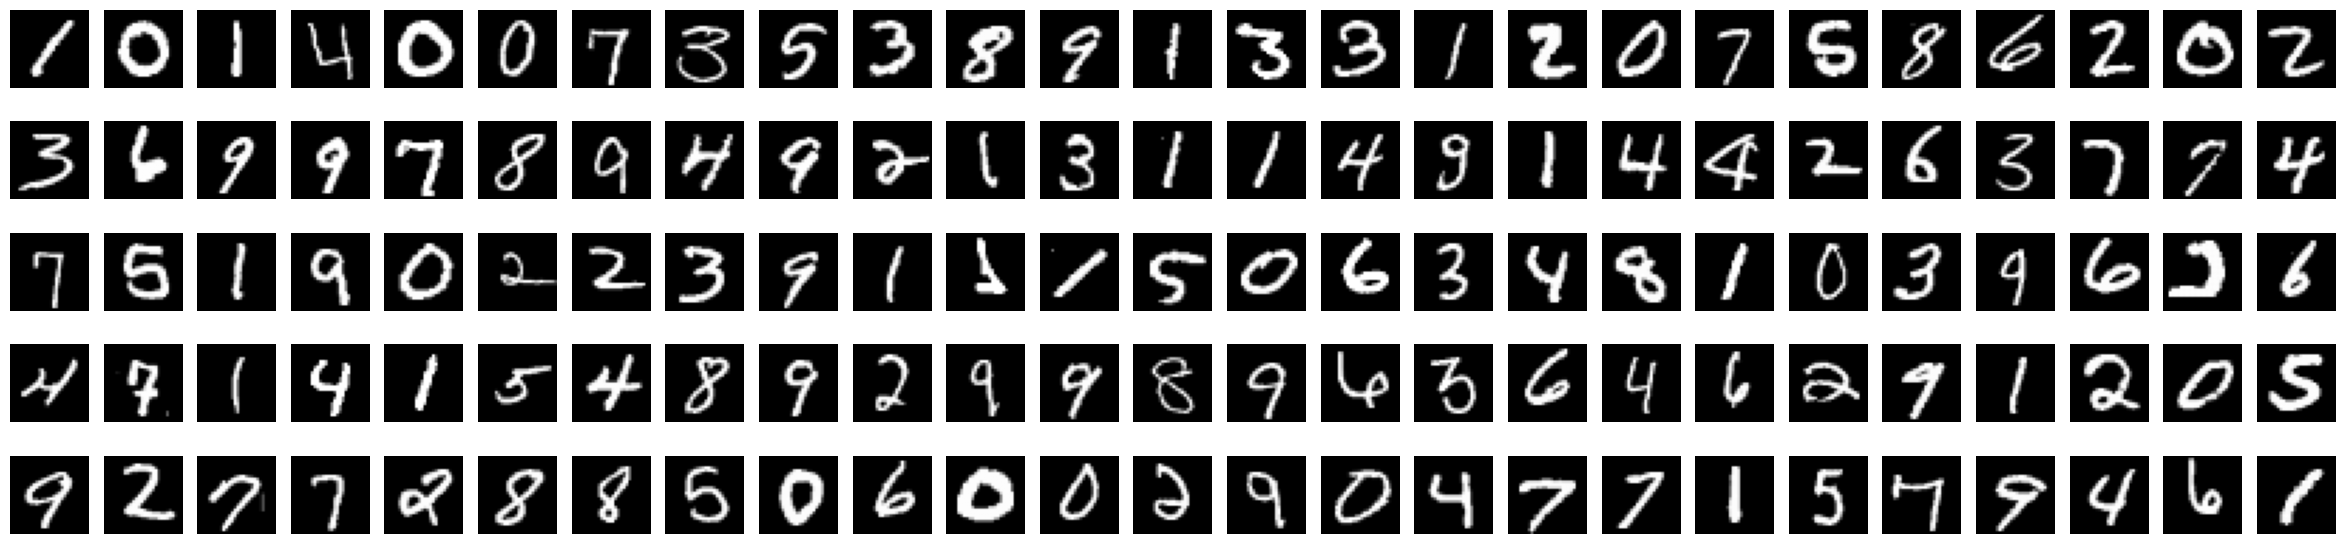

In [6]:
# Step 2a: Visualize original images

plt.figure(figsize=(30, 7))

for i in range(125):    
    plt.subplot(5, 25, i + 1)
    plt.imshow(mnist2.iloc[i].to_numpy().reshape(28, 28), cmap='gray')
    plt.axis('off')

In [7]:
#Step 3
# We will now scale the dataset. 
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()
scaled_data = scale.fit_transform(mnist2)
scaled_data

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(42000, 784))

In [8]:
scaled_data = pd.DataFrame(scaled_data,columns=mnist2.columns)
scaled_data.head()

,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.034737,-0.02527,-0.018026,-0.011473,-0.009099,-0.006897,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.034737,-0.02527,-0.018026,-0.011473,-0.009099,-0.006897,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.034737,-0.02527,-0.018026,-0.011473,-0.009099,-0.006897,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.034737,-0.02527,-0.018026,-0.011473,-0.009099,-0.006897,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.034737,-0.02527,-0.018026,-0.011473,-0.009099,-0.006897,0.0,0.0,0.0,0.0


In [9]:
#Step 4
# Center the data
mean_data = np.mean(scaled_data, axis=0)  #mean across row
centered_data = scaled_data - mean_data

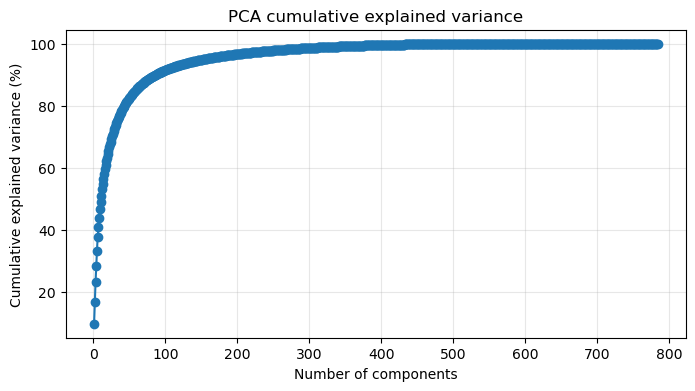

In [10]:
# Task 1: Eigen decomposition and explained variance
# Calculate covariance matrix
# cov_matrix = np.cov(centered_data.T)

# Tried using the centered data but it was gives same results when reconstructing the image. So I used the original mnist2 data instead. 
cov_matrix = np.cov(mnist2.T)

# Perform eigen decomposition
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Sort eigenvalues and eigenvectors by descending eigenvalues
idx = eigenvalues.argsort()[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Percentage of variance explained and cumulative variance
variance_explained = eigenvalues / eigenvalues.sum()
cum_variance_explained = np.cumsum(variance_explained)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_variance_explained) + 1), cum_variance_explained * 100, marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance (%)')
plt.title('PCA cumulative explained variance')
plt.grid(True, alpha=0.3)
plt.show()

In [11]:

# Task 2: PCA for dimensionality reduction for p in {50, 250, 300, 500, 600, 700}
reduced_data = {}
reconstructed_data = {}

for k in [50, 250, 300, 500, 600, 700]:
    V_p = eigenvectors[:, :k]
    Z_p = centered_data.values @ V_p
    reduced_data[k] = Z_p
    # X_hat_scaled = Z_p @ V_p.T + mean_data.to_numpy()
    X_hat_scaled = Z_p @ V_p.T
    X_hat_original = scale.inverse_transform(X_hat_scaled)
    reconstructed_data[k] = X_hat_original
    print(f'k = {k}: reduced shape = {Z_p.shape}, reconstructed shape = {X_hat_original.shape}')


k = 50: reduced shape = (42000, 50), reconstructed shape = (42000, 784)
k = 250: reduced shape = (42000, 250), reconstructed shape = (42000, 784)
k = 300: reduced shape = (42000, 300), reconstructed shape = (42000, 784)
k = 500: reduced shape = (42000, 500), reconstructed shape = (42000, 784)
k = 600: reduced shape = (42000, 600), reconstructed shape = (42000, 784)
k = 700: reduced shape = (42000, 700), reconstructed shape = (42000, 784)


In [16]:
from math import log10, sqrt
import numpy as np

def PSNR(original, compressed):
    mse = np.mean((original - compressed) ** 2)
    if(mse == 0):  # MSE is zero means no noise is present in the signal .
                  # Therefore PSNR have no importance.
        return 100
    max_pixel = 255.0
    psnr = 20 * log10(max_pixel / sqrt(mse))
    return psnr

,n_components,mean_psnr
0,50,18.780635
1,250,27.030395
2,300,29.507998
3,500,56.165104
4,600,83.994316


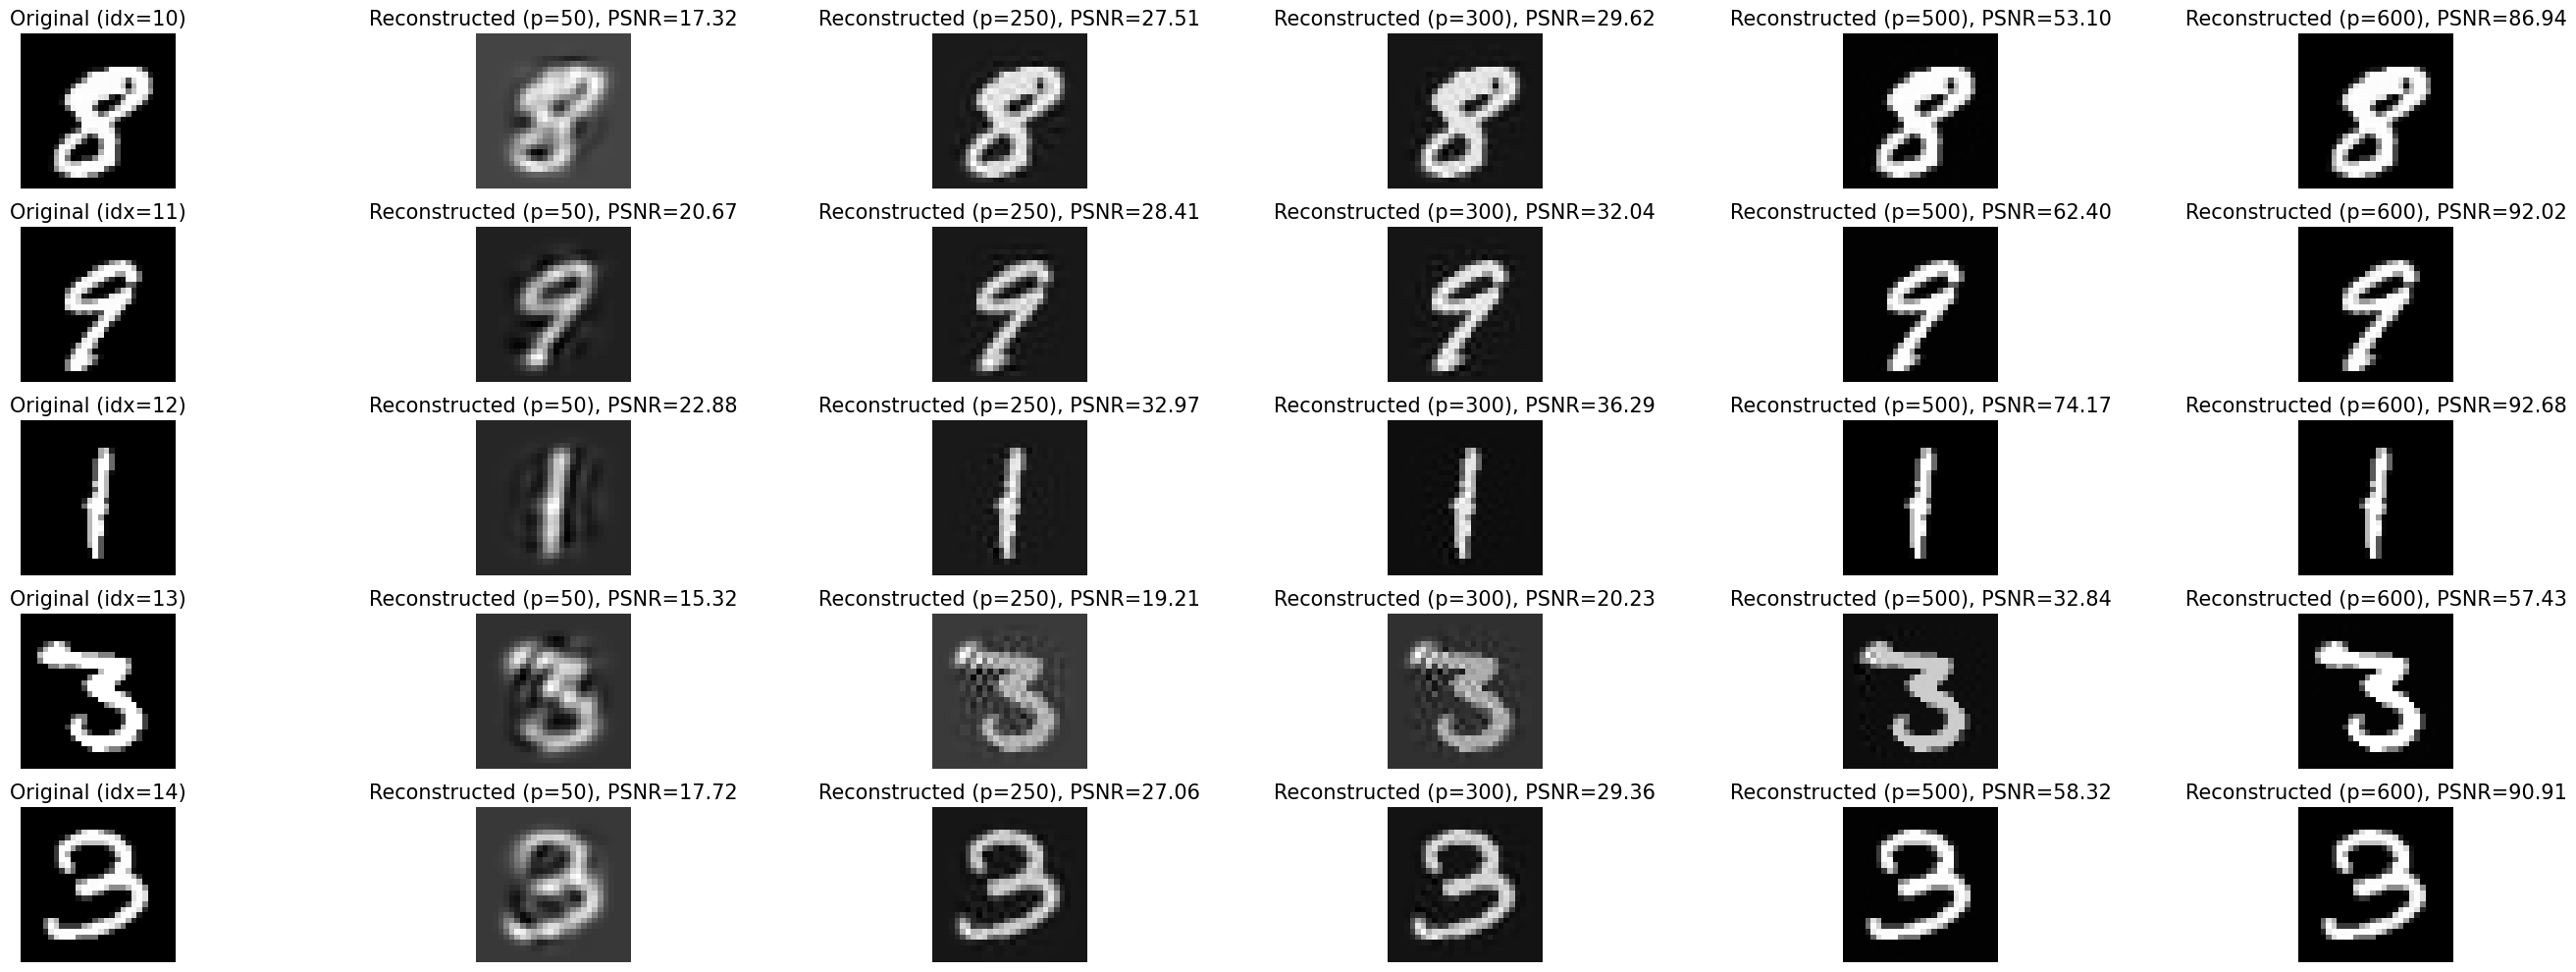

In [17]:
# Task 3: Reconstruct and visualize original vs reconstructed images

# fig, axes = plt.subplots(1, 7, figsize=(30, 7))

# visualize multiple rows: original + reconstructions
ps = [50, 250, 300, 500, 600]
n_rows = 5
sample_idx = 10
sample_indices = list(range(sample_idx, sample_idx + n_rows))

fig, axes = plt.subplots(n_rows, len(ps) + 1, figsize=(30, 10))
axes = np.array(axes).reshape(n_rows, len(ps) + 1)

for r, idx in enumerate(sample_indices):
    # original
    orig = mnist2.iloc[idx].to_numpy().reshape(28, 28)
    ax = axes[r, 0]
    ax.imshow(orig, cmap='gray')
    ax.set_title(f'Original (idx={idx})', fontsize=15)
    ax.axis('off')

    if r == 0:
        psnr_by_comp = {}
        for p in ps:
            comp_psnr = []
            for idx2 in sample_indices:
                orig2 = mnist2.iloc[idx2].to_numpy().reshape(28, 28)
                recon2 = reconstructed_data[p][idx2].reshape(28, 28)
                comp_psnr.append(PSNR(orig2, recon2))
            psnr_by_comp[p] = np.mean(comp_psnr)

        mean_psnr_df = pd.DataFrame({
            'n_components': list(psnr_by_comp.keys()),
            'mean_psnr': list(psnr_by_comp.values())
        })
        display(mean_psnr_df)
    # reconstructions
    for c, p in enumerate(ps, start=1):
        recon = reconstructed_data[p][idx].reshape(28, 28)
        value = PSNR(orig, recon)
        ax = axes[r, c]
        ax.imshow(recon, cmap='gray')
        ax.set_title(f'Reconstructed (p={p}), PSNR={value:.2f}', fontsize=15)
        ax.axis('off')

plt.tight_layout()
plt.show()

### PCA using scikit-learn

The following cells perform the same dimensionality reduction and image reconstruction as the manual eigen-decomposition approach, but use sklearn.decomposition.

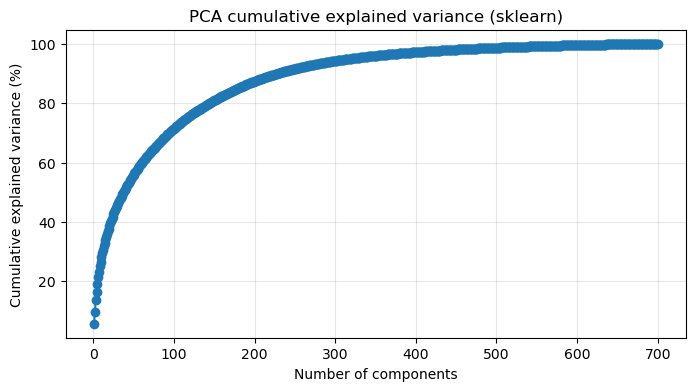

In [23]:
from sklearn.decomposition import PCA

X_scaled = scaled_data.values

# fit PCA on the standardized data
pca = PCA(n_components=700, svd_solver='randomized', random_state=42)
Z_700 = pca.fit_transform(X_scaled)

# explained variance plot
cum_variance_explained = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(cum_variance_explained) + 1), cum_variance_explained * 100, marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance (%)')
plt.title('PCA cumulative explained variance (sklearn)')
plt.grid(True, alpha=0.3)
plt.show()


In [24]:

# reduce and reconstruct for selected component counts
selected_components = [50, 250, 300, 500, 600, 700]
reduced_data_pca = {}
reconstructed_data_pca = {}

for k in selected_components:
    Z_k = Z_700[:, :k]
    X_hat_scaled = Z_k @ pca.components_[:k, :]
    X_hat_original = scale.inverse_transform(X_hat_scaled)
    reduced_data_pca[k] = Z_k
    reconstructed_data_pca[k] = X_hat_original
    print(f'k = {k}: reduced shape = {Z_k.shape}, reconstructed shape = {X_hat_original.shape}')



k = 50: reduced shape = (42000, 50), reconstructed shape = (42000, 784)
k = 250: reduced shape = (42000, 250), reconstructed shape = (42000, 784)
k = 300: reduced shape = (42000, 300), reconstructed shape = (42000, 784)
k = 500: reduced shape = (42000, 500), reconstructed shape = (42000, 784)
k = 600: reduced shape = (42000, 600), reconstructed shape = (42000, 784)
k = 700: reduced shape = (42000, 700), reconstructed shape = (42000, 784)


,n_components,mean_psnr_pca
0,50,17.396841
1,250,22.770651
2,300,23.909607
3,500,28.064000
4,600,31.768068


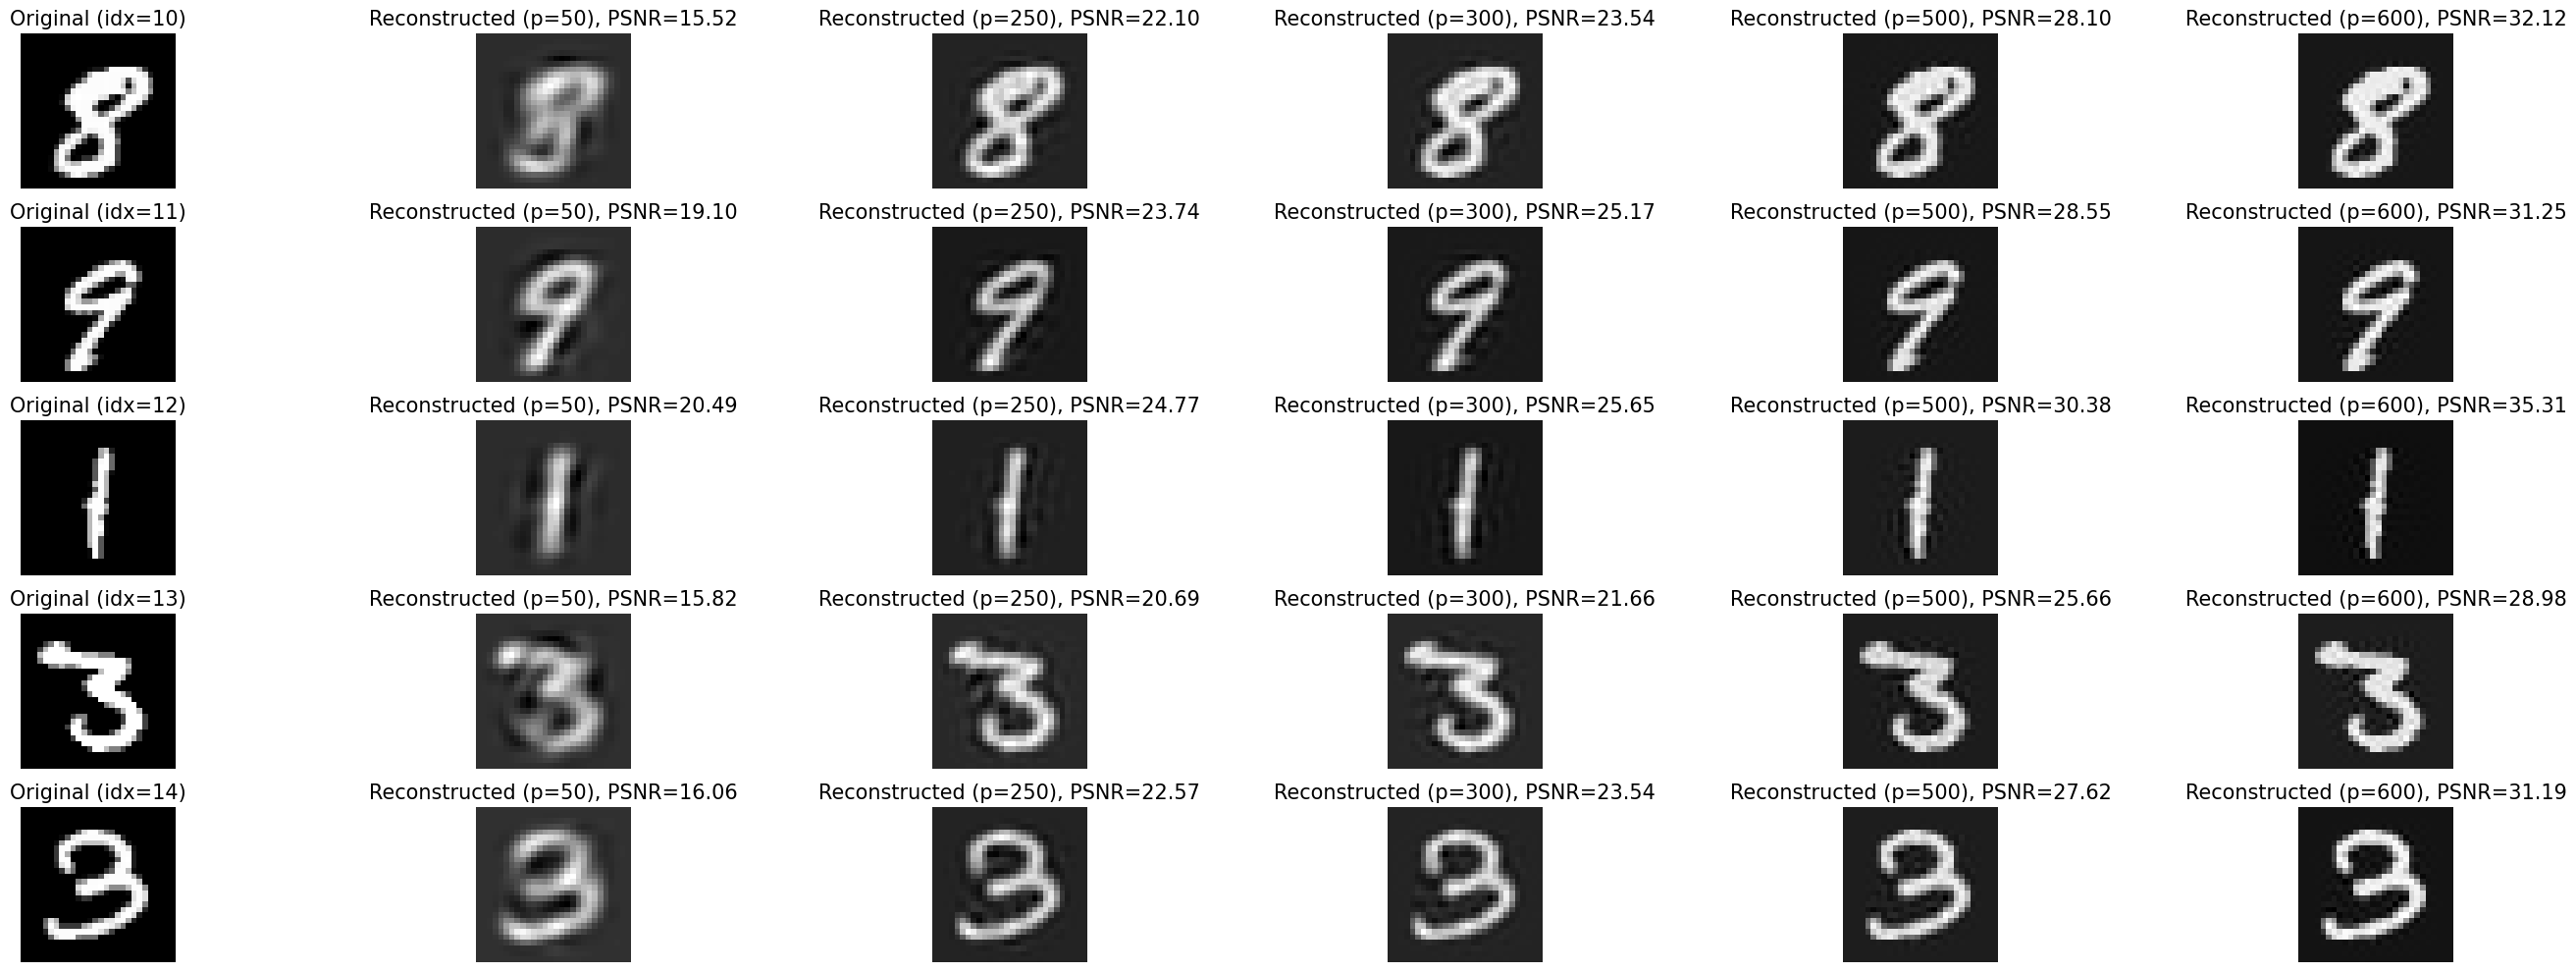

In [25]:
# visualize original vs reconstructed images
ps = [50, 250, 300, 500, 600]
n_rows = 5

fig, axes = plt.subplots(n_rows, len(ps) + 1, figsize=(30, 10))
axes = np.array(axes).reshape(n_rows, len(ps) + 1)

for r, idx in enumerate(sample_indices):
    # original
    orig = mnist2.iloc[idx].to_numpy().reshape(28, 28)
    ax = axes[r, 0]
    ax.imshow(orig, cmap='gray')
    ax.set_title(f'Original (idx={idx})', fontsize=15)
    ax.axis('off')

    if r == 0:
        psnr_by_comp_pca = {}
        for p in ps:
            comp_psnr = []
            for idx2 in sample_indices:
                orig2 = mnist2.iloc[idx2].to_numpy().reshape(28, 28)
                recon2 = reconstructed_data_pca[p][idx2].reshape(28, 28)
                comp_psnr.append(PSNR(orig2, recon2))
            psnr_by_comp_pca[p] = np.mean(comp_psnr)

        mean_psnr_df_pca = pd.DataFrame({
            'n_components': list(psnr_by_comp_pca.keys()),
            'mean_psnr_pca': list(psnr_by_comp_pca.values())
        })
        display(mean_psnr_df_pca)
    # reconstructions
    for c, p in enumerate(ps, start=1):
        recon = reconstructed_data_pca[p][idx].reshape(28, 28)
        value = PSNR(orig, recon)
        ax = axes[r, c]
        ax.imshow(recon, cmap='gray')
        ax.set_title(f'Reconstructed (p={p}), PSNR={value:.2f}', fontsize=15)
        ax.axis('off')

plt.tight_layout()
plt.show()